# Exploratory Data Analysis

## Library Imports

In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from urllib.parse import quote_plus
from pathlib import Path

## Load Data & Build MySQL Database

In [63]:
# load to dataframes
invoices = pd.read_pickle("../Data/Cleaned/invoices_cleaned.pkl")
invoice_charges = pd.read_pickle('../Data/Cleaned/invoice_charges_cleaned.pkl')
payments = pd.read_pickle('../Data/Cleaned/payments_cleaned.pkl')
projects = pd.read_pickle('../Data/Cleaned/projects_cleaned.pkl')
vendors = pd.read_pickle('../Data/Cleaned/vendors_cleaned.pkl')

# note: pickle files were excluded from repository. Run 'data_cleaning.ipynb' to create pickle files.

In [64]:
# connect to MySQL
load_dotenv(dotenv_path=Path("../.env"))

user = os.getenv("MYSQL_USER")
password = quote_plus(os.getenv("MYSQL_PASSWORD"))
host = os.getenv("MYSQL_HOST")
port = os.getenv("MYSQL_PORT")
database = os.getenv("MYSQL_DATABASE")

In [65]:
# connect to MySQL
engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}"
)

# create database and reconnect
with engine.connect() as conn:
    conn.execute(text(f"CREATE DATABASE IF NOT EXISTS {database}"))

engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"
)

# test the connection
query = """
SELECT DATABASE();
"""

pd.read_sql_query(query, engine)

,DATABASE()
0,ap_project


In [66]:
# load dataframes into MySQL
vendors.to_sql("vendors", engine, if_exists="replace", index=False)
projects.to_sql("projects", engine, if_exists="replace", index=False)
invoices.to_sql("invoices", engine, if_exists="replace", index=False)
payments.to_sql("payments", engine, if_exists="replace", index=False)
invoice_charges.to_sql("invoice_charges", engine, if_exists="replace", index=False)

# confirm tables loaded
query = """
SHOW TABLES;
"""

pd.read_sql_query(query, engine)

,Tables_in_ap_project
0,invoice_charges
1,invoices
2,payments
3,projects
4,vendors
5,vw_ap_spend_detail
6,vw_vendor_detail


In [67]:
# check row counts
query = """
SELECT 'vendors' AS table_name, COUNT(*) AS row_count FROM vendors
UNION ALL
SELECT 'projects', COUNT(*) FROM projects
UNION ALL
SELECT 'invoices', COUNT(*) FROM invoices
UNION ALL
SELECT 'payments', COUNT(*) FROM payments
UNION ALL
SELECT 'invoice_charges', COUNT(*) FROM invoice_charges;
"""

row_counts = pd.read_sql_query(query, engine)
row_counts

,table_name,row_count
0,vendors,100
1,projects,50
2,invoices,1000
3,payments,1126
4,invoice_charges,2510


In [68]:
# Preview one joined table to confirm relationships are working
query = """
SELECT
    i.invoice_id,
    i.invoice_number,
    v.vendor_name,
    v.vendor_type,
    i.invoice_date,
    i.due_date,
    p.payment_date,
    i.invoice_amount
FROM invoices i
LEFT JOIN payments p
    ON i.invoice_id = p.invoice_id
JOIN vendors v
    ON i.vendor_id = v.vendor_id
LIMIT 10;
"""

pd.read_sql_query(query, engine)

,invoice_id,invoice_number,vendor_name,vendor_type,invoice_date,due_date,payment_date,invoice_amount
0,INV000001,50188-430,RB Mac Construction Co Inc,Vendor,2025-12-29,2026-02-12,2026-03-04,58912.34
1,INV000002,30728-872,Posylio GC Corp,Vendor,2025-01-25,2025-03-11,2025-04-09,62327.30
2,INV000002,30728-872,Posylio GC Corp,Vendor,2025-01-25,2025-03-11,2025-03-04,62327.30
3,INV000003,94834-463,OP-Tech Environmental Services Inc,Subconsultant,2023-11-14,2024-01-13,2024-01-26,56412.67
4,INV000004,62470-544,Bison Elevator Service Inc,Vendor,2024-06-06,2024-08-05,2024-08-25,2152.84
5,INV000004,62470-544,Bison Elevator Service Inc,Vendor,2024-06-06,2024-08-05,2024-09-17,2152.84
6,INV000004,62470-544,Bison Elevator Service Inc,Vendor,2024-06-06,2024-08-05,2024-08-04,2152.84
7,INV000005,83954-320,American Jail Products LLC,Vendor,2024-03-23,2024-04-22,2024-04-22,33368.21
8,INV000006,31315-683,Raw Power Electric Corp,Vendor,2025-12-01,2026-01-15,NaT,62620.46
9,INV000007,93581-560,Empire Mechanical Services Inc,Vendor,2025-01-05,2025-02-19,2025-04-04,15310.38


## Data Analysis and Visualizations

1. AP Spend Overview
2. Vendor Spend Analysis
3. Project Cost Analysis
4. Invoice Charge Breakdown
5. Payment Performance
6. Cash Flow Trends

### 1. AP Spend Overview

#### Overall AP spend summary

In [69]:
query = """
WITH payment_totals AS (
    SELECT
        invoice_id,
        SUM(payment_amount) AS total_paid_amount
    FROM payments
    GROUP BY invoice_id
),

invoice_summary AS (
    SELECT
        COUNT(DISTINCT i.invoice_id) AS total_invoices,
        COUNT(DISTINCT i.vendor_id) AS vendors_involved,
        ROUND(SUM(i.invoice_amount), 2) AS total_invoice_spend,
        ROUND(SUM(COALESCE(pt.total_paid_amount, 0)), 2) AS total_paid_amount,
        ROUND(
            SUM(i.invoice_amount) - SUM(COALESCE(pt.total_paid_amount, 0)),
            2
        ) AS total_unpaid_amount,
        ROUND(
            100.0 * SUM(COALESCE(pt.total_paid_amount, 0)) / SUM(i.invoice_amount),
            1
        ) AS percent_paid
    FROM invoices i
    LEFT JOIN payment_totals pt
        ON i.invoice_id = pt.invoice_id
),

project_summary AS (
    SELECT
        COUNT(DISTINCT project_id) AS total_projects
    FROM projects
),

ap_project_summary AS (
    SELECT
        COUNT(DISTINCT project_id) AS projects_with_ap_charges
    FROM invoice_charges
)

SELECT
    invoice_summary.total_invoices,
    invoice_summary.vendors_involved,
    project_summary.total_projects,
    ap_project_summary.projects_with_ap_charges,
    invoice_summary.total_invoice_spend,
    invoice_summary.total_paid_amount,
    invoice_summary.total_unpaid_amount,
    invoice_summary.percent_paid

FROM invoice_summary
CROSS JOIN project_summary
CROSS JOIN ap_project_summary;
"""

ap_spend_overview = pd.read_sql_query(query, engine)
ap_spend_overview

,total_invoices,vendors_involved,total_projects,projects_with_ap_charges,total_invoice_spend,total_paid_amount,total_unpaid_amount,percent_paid
0,1000,100,50,50,41536472.74,33564772.55,7971700.19,80.8


#### Paid vs. unpaid invoice summary as of 5/26/2026

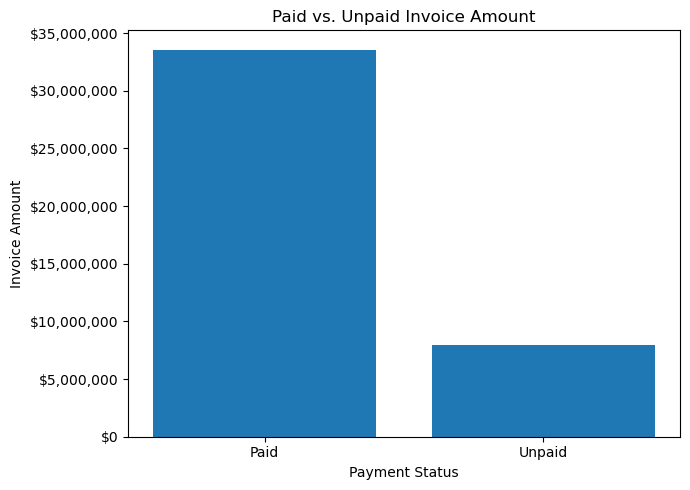

In [70]:
paid_unpaid = ap_spend_overview[[
    "total_paid_amount",
    "total_unpaid_amount"
]].T.reset_index()

paid_unpaid.columns = ["payment_status", "amount"]

paid_unpaid["payment_status"] = paid_unpaid["payment_status"].replace({
    "total_paid_amount": "Paid",
    "total_unpaid_amount": "Unpaid"
})

plt.figure(figsize=(7, 5))

plt.bar(
    paid_unpaid["payment_status"],
    paid_unpaid["amount"]
)

plt.title("Paid vs. Unpaid Invoice Amount")
plt.xlabel("Payment Status")
plt.ylabel("Invoice Amount")

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.tight_layout()
plt.show()

#### Total invoice spend and invoice count by vendor type

In [71]:
query = """
SELECT
    v.vendor_type,

    COUNT(DISTINCT i.invoice_id) AS invoice_count,

    COUNT(DISTINCT v.vendor_id) AS vendor_count,

    ROUND(SUM(i.invoice_amount), 2) AS total_invoice_spend,

    ROUND(AVG(i.invoice_amount), 2) AS avg_invoice_amount

FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id

GROUP BY v.vendor_type
ORDER BY total_invoice_spend DESC;
"""

spend_by_vendor_type = pd.read_sql_query(query, engine)
spend_by_vendor_type

,vendor_type,invoice_count,vendor_count,total_invoice_spend,avg_invoice_amount
0,Vendor,814,82,33551268.60,41217.77
1,Subconsultant,186,18,7985204.14,42931.21


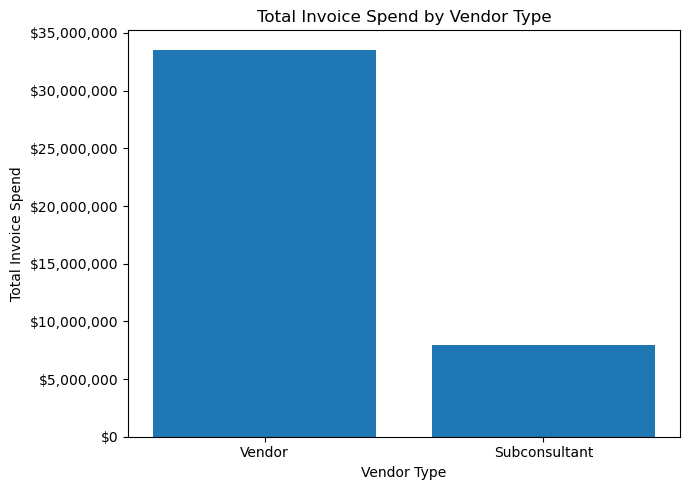

In [72]:
plt.figure(figsize=(7, 5))

plt.bar(
    spend_by_vendor_type["vendor_type"],
    spend_by_vendor_type["total_invoice_spend"]
)

plt.title("Total Invoice Spend by Vendor Type")
plt.xlabel("Vendor Type")
plt.ylabel("Total Invoice Spend")

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.tight_layout()
plt.show()

### 2. Vendor Spend Analysis

In [73]:
# Top vendors by total invoice amount
query = """
SELECT
    v.vendor_id,
    v.vendor_name,
    COUNT(i.invoice_id) AS invoice_count,
    ROUND(SUM(i.invoice_amount), 2) AS total_invoice_amount,
    ROUND(AVG(i.invoice_amount), 2) AS avg_invoice_amount
FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
GROUP BY
    v.vendor_id,
    v.vendor_name
ORDER BY total_invoice_amount DESC;
"""

vendor_spend = pd.read_sql_query(query, engine)

vendor_spend

,vendor_id,vendor_name,invoice_count,total_invoice_amount,avg_invoice_amount
0,V0072,OP-Tech Environmental Services Inc,16,817995.09,51124.69
1,V0085,Ran Fire Protection Engineering PC,18,816134.41,45340.80
2,V0021,American Pump & Tank Installation Co Inc,16,733088.12,45818.01
3,V0095,Reliant Electrical Contracting Inc,17,704063.22,41415.48
4,V0025,Anjac Enterprises Inc,15,696306.19,46420.41
...,...,...,...,...,...
95,V0028,Bayside Refrigeration Inc,4,163374.46,40843.62
96,V0033,Black Horse Group LLC,5,147158.97,29431.79
97,V0006,A Peter Luger Construction Inc,6,133806.52,22301.09
98,V0066,New Century Electric Inc,5,77526.59,15505.32


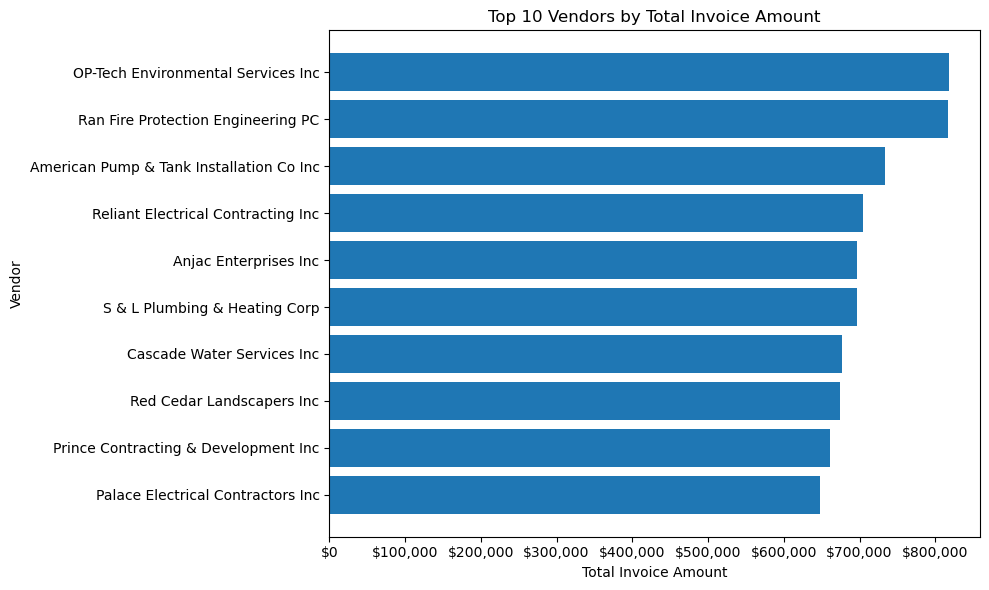

In [74]:
# Horizontal bar chart: Top 10 vendors by spend

top_10_vendor_spend = vendor_spend.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_10_vendor_spend["vendor_name"],
    top_10_vendor_spend["total_invoice_amount"]
)

plt.title("Top 10 Vendors by Total Invoice Amount")
plt.xlabel("Total Invoice Amount")
plt.ylabel("Vendor")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [75]:
# Invoice count by vendor
query = """
SELECT
    v.vendor_id,
    v.vendor_name,
    COUNT(i.invoice_id) AS invoice_count
FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
GROUP BY
    v.vendor_id,
    v.vendor_name
ORDER BY invoice_count DESC;
"""

invoice_count_by_vendor = pd.read_sql_query(query, engine)

invoice_count_by_vendor

,vendor_id,vendor_name,invoice_count
0,V0087,Ray S Pantel Inc,19
1,V0085,Ran Fire Protection Engineering PC,18
2,V0095,Reliant Electrical Contracting Inc,17
3,V0084,Prince Contracting & Development Inc,16
4,V0003,514 Potter Ave Corp,16
...,...,...,...
95,V0031,Biltwel General Contractor Corp,5
96,V0066,New Century Electric Inc,5
97,V0024,Andron Construction Corp,4
98,V0028,Bayside Refrigeration Inc,4


In [76]:
# average invoice amount by vendor
query = """
SELECT
    v.vendor_id,
    v.vendor_name,
    ROUND(AVG(i.invoice_amount), 2) AS avg_invoice_amount
FROM invoices i
JOIN vendors v
    ON i.vendor_id = v.vendor_id
GROUP BY
    v.vendor_id,
    v.vendor_name
ORDER BY avg_invoice_amount DESC;
"""

avg_invoice_amount = pd.read_sql_query(query, engine)

avg_invoice_amount

,vendor_id,vendor_name,avg_invoice_amount
0,V0069,OCS Industries,74495.28
1,V0013,Ajay Glass & Mirror Co Inc,60879.23
2,V0038,C&S Technical Resources Inc,57400.99
3,V0097,RSI Roofing Inc,56867.12
4,V0048,Crisafulli Brothers Plumbing & Heating,56573.83
...,...,...,...
95,V0029,BBL Construction Services LLC,27623.53
96,V0002,192 Branch Interior Services Inc,27270.59
97,V0006,A Peter Luger Construction Inc,22301.09
98,V0066,New Century Electric Inc,15505.32


In [77]:
# Identify vendor spend outliers with the IQR method
Q1 = vendor_spend["total_invoice_amount"].quantile(0.25)
Q3 = vendor_spend["total_invoice_amount"].quantile(0.75)

# calculate the interquartile range - the spread of the middle 50% of vendor spend values
IQR = Q3 - Q1
upper_limit = Q3 + (1.5 * IQR)

vendor_spend_outliers = vendor_spend[
    vendor_spend["total_invoice_amount"] > upper_limit
].sort_values("total_invoice_amount", ascending=False)

vendor_spend_outliers

,vendor_id,vendor_name,invoice_count,total_invoice_amount,avg_invoice_amount
0,V0072,OP-Tech Environmental Services Inc,16,817995.09,51124.69
1,V0085,Ran Fire Protection Engineering PC,18,816134.41,45340.80


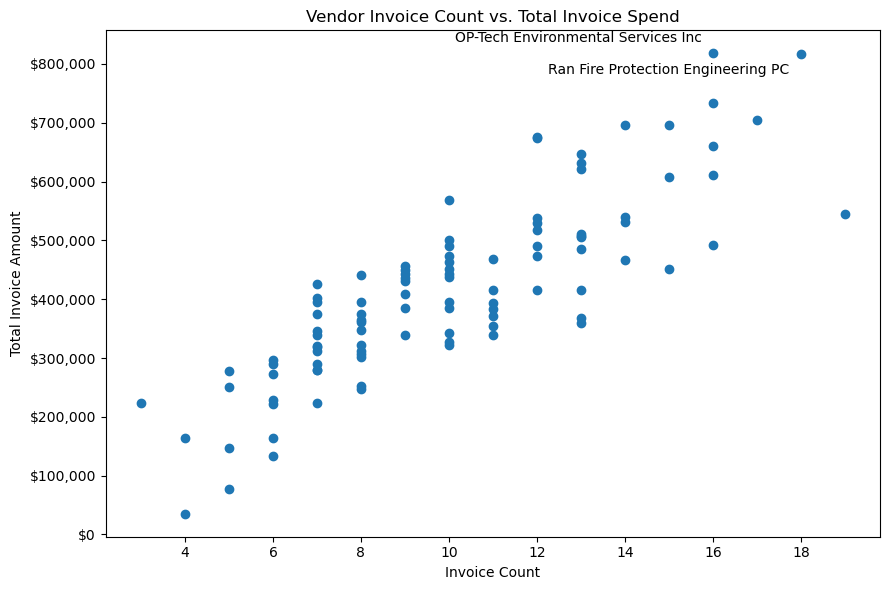

In [78]:
# scatter plot to explore why a vendor has high spend

plt.figure(figsize=(9, 6))

plt.scatter(
    vendor_spend["invoice_count"],
    vendor_spend["total_invoice_amount"]
)

plt.title("Vendor Invoice Count vs. Total Invoice Spend")
plt.xlabel("Invoice Count")
plt.ylabel("Total Invoice Amount")

plt.gca().yaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

# alternate label positions (above-left, below-left) so labels don't overlap
label_offsets = [(-8, 8), (-8, -14)]

for i, (_, row) in enumerate(vendor_spend_outliers.iterrows()):
    plt.annotate(
        row["vendor_name"],
        (row["invoice_count"], row["total_invoice_amount"]),
        xytext=label_offsets[i % len(label_offsets)],
        textcoords="offset points",
        ha="right"
    )

plt.tight_layout()
plt.show()

For PowerBI:
* top 10 of the above stats
* vendors with the most payments
* what outliers can be found in this dataset?
* if vendor terms from invoice don't match payment terms in the system, advise a review of the client's contract

### 3. Project Cost Analysis

Which projects generate the highest vendor costs?

Are costs concentrated in a few projects?

Which project types drive the most AP spend?


Good queries/visuals:

Top 10 projects by total vendor cost

Spend by project type

Invoice count by project

Average charge amount by project

good chart:

Horizontal bar chart: Top 10 projects by vendor cost

In [82]:
# Which projects have the highest vendor spend? (client projects only)

query = """
SELECT
    p.project_id,
    p.project_name,
    p.project_status,
    COUNT(DISTINCT c.invoice_id) AS invoice_count,
    COUNT(*) AS charge_count,
    ROUND(SUM(c.charge_amount), 2) AS total_vendor_cost,
    ROUND(AVG(c.charge_amount), 2) AS avg_charge
FROM invoice_charges c
JOIN projects p ON c.project_id = p.project_id
WHERE p.project_type = 'project'
GROUP BY p.project_id, p.project_name, p.project_status
ORDER BY total_vendor_cost DESC
LIMIT 10;
"""

top_10_projects = pd.read_sql_query(text(query), engine)
top_10_projects

,project_id,project_name,project_status,invoice_count,charge_count,total_vendor_cost,avg_charge
0,PRJ-0020,Corporate Headquarters Renovation,Active,54,56,1235390.33,22060.54
1,PRJ-0019,Hospital Emergency Wing,Active,60,60,1198979.62,19982.99
2,PRJ-0011,Northside Elementary School,Planning,61,61,1156020.39,18951.15
3,PRJ-0030,Intermodal Rail Facility,Active,59,60,1133642.50,18894.04
4,PRJ-0010,Regional Water Treatment Upgrade,Active,66,66,1117482.95,16931.56
5,PRJ-0021,Regional Distribution Center,Active,61,64,1057214.82,16518.98
6,PRJ-0002,Albany Medical Center Expansion,Active,59,62,1014916.03,16369.61
7,PRJ-0026,Regional Library Construction,Planning,51,53,993867.97,18752.23
8,PRJ-0003,Capital Region Bridge Rehabilitation,Active,49,51,959316.77,18810.13
9,PRJ-0022,Urban Streetscape Improvement,Active,48,50,918864.28,18377.29


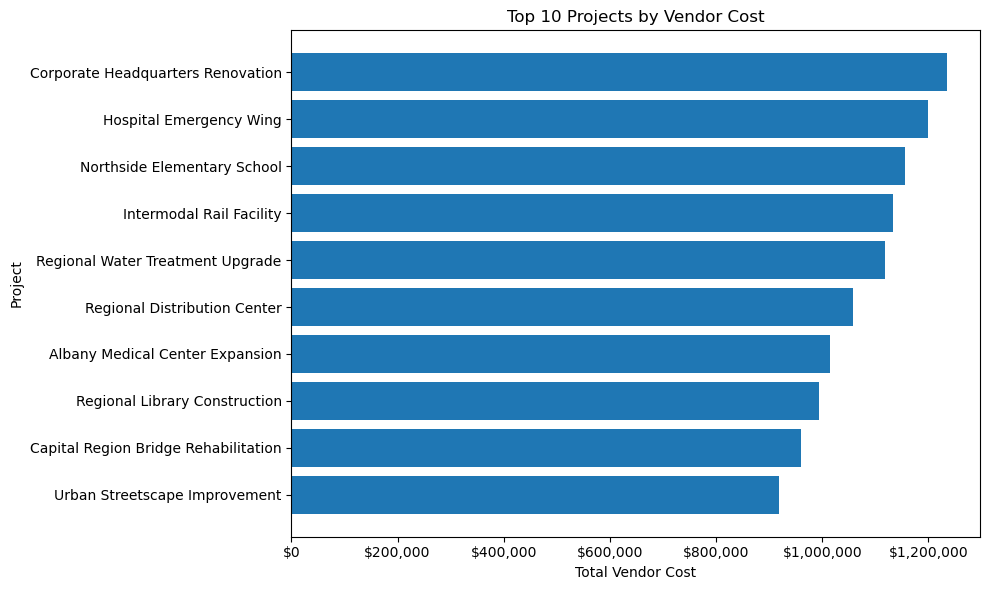

In [83]:
# Horizontal bar chart: top 10 client projects by vendor cost
plt.figure(figsize=(10, 6))

plt.barh(
    top_10_projects["project_name"],
    top_10_projects["total_vendor_cost"]
)

plt.title("Top 10 Projects by Vendor Cost")
plt.xlabel("Total Vendor Cost")
plt.ylabel("Project")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("${x:,.0f}")
)

plt.gca().invert_yaxis()   # largest project at the top
plt.tight_layout()
plt.show()

In [84]:
# Q2: Is vendor spend concentrated in a few projects?
# pct_of_total    = each project's share of all client-project vendor spend
# cumulative_pct  = share covered by that project plus all larger ones

query = """
WITH project_cost AS (
    SELECT
        p.project_id,
        p.project_name,
        ROUND(SUM(c.charge_amount), 2) AS total_vendor_cost
    FROM invoice_charges c
    JOIN projects p ON c.project_id = p.project_id
    WHERE p.project_type = 'project'
    GROUP BY p.project_id, p.project_name
)
SELECT
    project_id,
    project_name,
    total_vendor_cost,
    ROUND(100 * total_vendor_cost / SUM(total_vendor_cost) OVER (), 1) AS pct_of_total,
    ROUND(100 * SUM(total_vendor_cost) OVER (ORDER BY total_vendor_cost DESC)
          / SUM(total_vendor_cost) OVER (), 1) AS cumulative_pct
FROM project_cost
ORDER BY total_vendor_cost DESC;
"""

project_concentration = pd.read_sql_query(text(query), engine)

# If spend were perfectly even, the top 10 of 40 projects would be 25% of the total
top_10_share = project_concentration.loc[9, "cumulative_pct"]
print(f"Top 10 of {len(project_concentration)} client projects = {top_10_share}% of client-project vendor spend")

project_concentration.head(10)

Top 10 of 40 client projects = 32.0% of client-project vendor spend


,project_id,project_name,total_vendor_cost,pct_of_total,cumulative_pct
0,PRJ-0020,Corporate Headquarters Renovation,1235390.33,3.7,3.7
1,PRJ-0019,Hospital Emergency Wing,1198979.62,3.6,7.2
2,PRJ-0011,Northside Elementary School,1156020.39,3.4,10.7
3,PRJ-0030,Intermodal Rail Facility,1133642.50,3.4,14.0
4,PRJ-0010,Regional Water Treatment Upgrade,1117482.95,3.3,17.4
5,PRJ-0021,Regional Distribution Center,1057214.82,3.1,20.5
6,PRJ-0002,Albany Medical Center Expansion,1014916.03,3.0,23.5
7,PRJ-0026,Regional Library Construction,993867.97,3.0,26.5
8,PRJ-0003,Capital Region Bridge Rehabilitation,959316.77,2.9,29.3
9,PRJ-0022,Urban Streetscape Improvement,918864.28,2.7,32.0


In [85]:
# Q3: How does vendor spend compare to each project's budget?
# pct_of_budget = vendor spend / budget_amount

query = """
SELECT
    p.project_id,
    p.project_name,
    p.project_type,
    p.project_status,
    p.budget_amount,
    ROUND(SUM(c.charge_amount), 2) AS vendor_cost,
    ROUND(100 * SUM(c.charge_amount) / p.budget_amount, 1) AS pct_of_budget
FROM projects p
LEFT JOIN invoice_charges c ON c.project_id = p.project_id
GROUP BY p.project_id, p.project_name, p.project_type, p.project_status, p.budget_amount
ORDER BY pct_of_budget DESC;
"""

project_budget = pd.read_sql_query(text(query), engine)

# summary by project type: how much of budget has vendor spend used?
print(project_budget.groupby("project_type")["pct_of_budget"].describe().round(1))
print("Projects over 100% of budget:", (project_budget["pct_of_budget"] > 100).sum())

project_budget.head(10)

              count   mean    std   min    25%    50%    75%    max
project_type                                                       
overhead       10.0  224.4  168.9  45.1  156.4  179.4  251.4  651.4
project        40.0   22.6   15.2   5.6   11.2   16.6   27.9   61.4
Projects over 100% of budget: 8


,project_id,project_name,project_type,project_status,budget_amount,vendor_cost,pct_of_budget
0,OH-0010,Company Events And Employee Engagement,overhead,Active,150000.0,977145.47,651.4
1,OH-0006,Corporate Training And Professional Development,overhead,Active,210000.0,647586.23,308.4
2,OH-0008,Legal And Compliance Activities,overhead,Active,275000.0,718630.96,261.3
3,OH-0009,Corporate Software Subscriptions And Licensing,overhead,Active,340000.0,754543.23,221.9
4,OH-0007,Corporate Accounting And Finance,overhead,Active,430000.0,827961.07,192.5
5,OH-0003,Human Resources And Recruiting,overhead,Active,420000.0,698874.94,166.4
6,OH-0005,Office Operations And Facilities,overhead,Active,580000.0,935303.48,161.3
7,OH-0004,Marketing And Business Development,overhead,Active,650000.0,1005900.68,154.8
8,OH-0002,Corporate IT Systems And Infrastructure,overhead,Active,950000.0,771146.44,81.2
9,PRJ-0024,Office Tower HVAC Upgrade,project,Active,1350000.0,829284.67,61.4


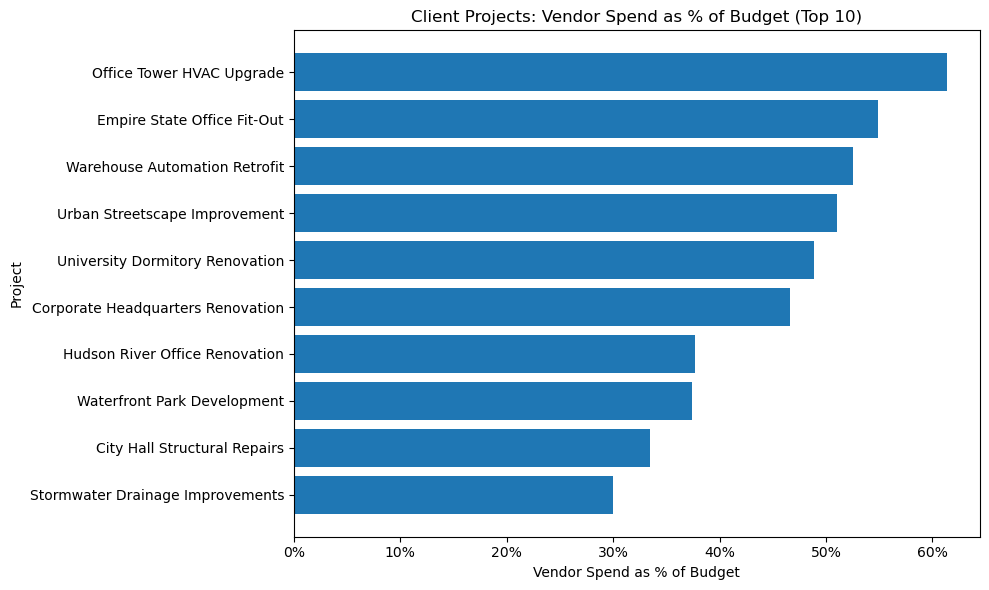

In [86]:
# Chart: client projects that have used the largest share of their budget
client_budget = project_budget[project_budget["project_type"] == "project"].head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    client_budget["project_name"],
    client_budget["pct_of_budget"]
)

plt.title("Client Projects: Vendor Spend as % of Budget (Top 10)")
plt.xlabel("Vendor Spend as % of Budget")
plt.ylabel("Project")

plt.gca().xaxis.set_major_formatter(
    mtick.StrMethodFormatter("{x:,.0f}%")
)

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [88]:
# Which project types drive the most AP spend? (client projects vs. overhead)

query = """
SELECT
    p.project_type,
    COUNT(DISTINCT p.project_id) AS project_count,
    COUNT(*) AS charge_count,
    ROUND(SUM(c.charge_amount), 2) AS total_vendor_cost,
    ROUND(SUM(c.charge_amount) / COUNT(DISTINCT p.project_id), 2) AS avg_cost_per_project,
    ROUND(100 * SUM(c.charge_amount) / (SELECT SUM(charge_amount) FROM invoice_charges), 1) AS pct_of_total_spend
FROM invoice_charges c
JOIN projects p ON c.project_id = p.project_id
GROUP BY p.project_type
ORDER BY total_vendor_cost DESC;
"""

spend_by_project_type = pd.read_sql_query(text(query), engine)
spend_by_project_type

,project_type,project_count,charge_count,total_vendor_cost,avg_cost_per_project,pct_of_total_spend
0,project,40,2016,33657657.19,841441.43,81.0
1,overhead,10,494,7878815.55,787881.55,19.0


### 4. Invoice Charge Breakdown

What charges exist within the costliest projects?

Which projects have many smaller charges vs. fewer large charges?

Which vendors contribute to the highest-cost projects?


Good queries/visuals:

Charge breakdown for top projects

Top charges by project

Vendor charges within each high-cost project

Charge count by project

Average charge amount by project

### 5. Payment Performance

How long does it take to pay invoices?

How often are invoices paid late?

Which vendors are most affected by late payments?

What dollar amount is associated with late payments?

queries/visuals:

Average days to pay

Late payment rate

Late paid invoice amount by vendor

Vendors never paid late

Average days late for late invoices only

good charts:

Top 10 vendors by late paid invoice amount

Late payment rate by vendor type

### 6. Cash Flow Trends

How much cash goes out each month?

Are AP payments stable or uneven?

Which months had the highest payment volume?

Are cash outflows driven more by vendors or subconsultants?


Good queries/visuals:

Monthly payment totals

Monthly invoice totals

Monthly payments by vendor type

Monthly payment count

Average monthly payment amount


Good chart:

Line chart: Monthly AP cash outflow